# InsightIQ — Customer Churn Analytics
## Notebook 1: Data Quality Checks and Exploratory Data Analysis

**Dataset:** IBM Telco Customer Churn public sample dataset  
**Objective:** Understand customer churn patterns and prepare a clean dataset for SQL analysis and machine learning.

## 1. Import libraries

If a library is missing, install it in your environment with `pip install pandas numpy matplotlib seaborn`.

In [3]:
import sys
import subprocess

print("Python executable:", sys.executable)

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "seaborn"
])

print("Seaborn installation completed!")

Python executable: c:\Users\91870\AppData\Local\Programs\Python\Python310\python.exe
Seaborn installation completed!


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Seaborn version:", sns.__version__)

All libraries imported successfully!
Seaborn version: 0.13.2


## 2. Load the dataset

Place `WA_Fn-UseC_-Telco-Customer-Churn.csv` in the `data/` folder next to this notebook's project directory. If your file is somewhere else, update `DATA_PATH`.

In [5]:
from pathlib import Path

DATA_PATH = Path(
  r"C:\Users\91870\Desktop\InsightIQ\Telco Customer Churn\WA_Fn-UseC_-Telco-Customer-Churn.csv"
)
df = pd.read_csv(DATA_PATH)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Rows: 7043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Inspect structure and data quality

In [6]:
print("Column types:")
display(df.dtypes.rename("dtype").to_frame())

print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Churn labels:", df["Churn"].value_counts(dropna=False).to_dict())

Column types:


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


Missing values by column:


,missing_count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Duplicate rows: 0
Duplicate customer IDs: 0
Churn labels: {'No': 5174, 'Yes': 1869}


## 4. Clean numeric fields

In [7]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing TotalCharges after conversion:", df["TotalCharges"].isna().sum())
display(df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head(10))

# For this dataset, blank TotalCharges commonly occurs for customers with zero tenure.
# Keep a cleaned copy and document any handling decision before modeling.
df_clean = df.copy()
df_clean["ChurnFlag"] = df_clean["Churn"].map({"No": 0, "Yes": 1})

Missing TotalCharges after conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


## 5. Key business KPIs

In [8]:
total_customers = len(df_clean)
churned_customers = int((df_clean["Churn"] == "Yes").sum())
churn_rate = df_clean["ChurnFlag"].mean()
avg_monthly_charges = df_clean["MonthlyCharges"].mean()
avg_tenure = df_clean["tenure"].mean()

kpis = pd.DataFrame({
    "Metric": ["Total customers", "Churned customers", "Churn rate", "Average monthly charges", "Average tenure (months)"],
    "Value": [total_customers, churned_customers, f"{churn_rate:.2%}", f"{avg_monthly_charges:.2f}", f"{avg_tenure:.2f}"]
})
display(kpis)

,Metric,Value
0,Total customers,7043
1,Churned customers,1869
2,Churn rate,26.54%
3,Average monthly charges,64.76
4,Average tenure (months),32.37


## 6. Churn distribution

,Customers
Churn,
No,5174
Yes,1869


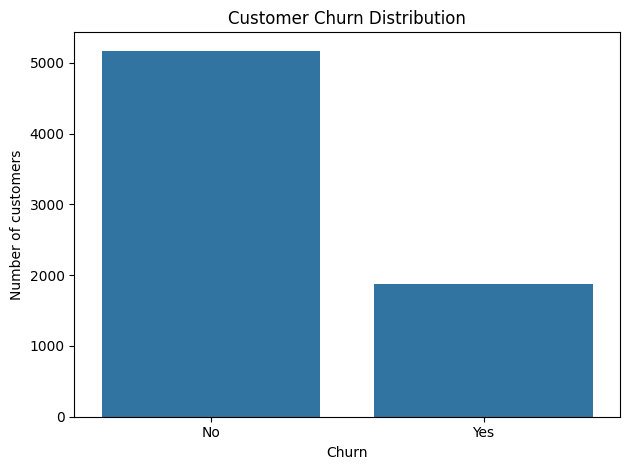

In [9]:
churn_counts = df_clean["Churn"].value_counts().reindex(["No", "Yes"])
display(churn_counts.rename_axis("Churn").to_frame("Customers"))

ax = sns.barplot(x=churn_counts.index, y=churn_counts.values)
ax.set(title="Customer Churn Distribution", xlabel="Churn", ylabel="Number of customers")
plt.tight_layout()
plt.show()

## 7. Churn by contract type

,customers,churn_rate,churn_rate_pct
Contract,,,
Month-to-month,3875,0.427097,42.71
One year,1473,0.112695,11.27
Two year,1695,0.028319,2.83


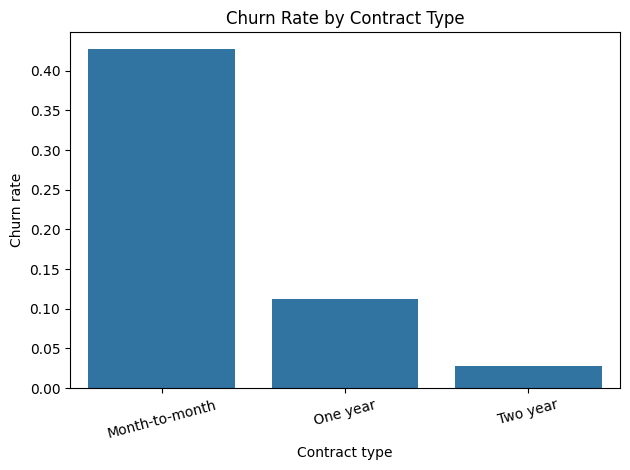

In [10]:
contract_churn = (
    df_clean.groupby("Contract", observed=False)["ChurnFlag"]
    .agg(customers="size", churn_rate="mean")
    .sort_values("churn_rate", ascending=False)
)
contract_churn["churn_rate_pct"] = (contract_churn["churn_rate"] * 100).round(2)
display(contract_churn)

sns.barplot(data=df_clean, x="Contract", y="ChurnFlag", errorbar=None)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract type")
plt.ylabel("Churn rate")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 8. Churn by tenure

,customers,churn_rate,churn_rate_pct
TenureGroup,,,
0–6,1481,0.529372,52.94
7–12,705,0.358865,35.89
13–24,1024,0.287109,28.71
25–48,1594,0.203890,20.39
49–60,832,0.144231,14.42
61–72,1407,0.066098,6.61


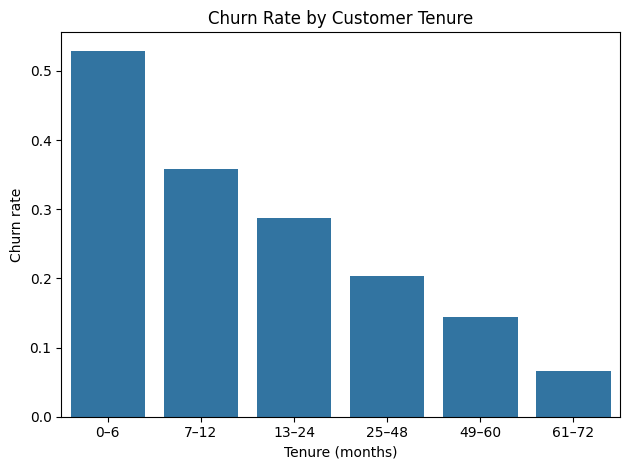

In [11]:
df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 6, 12, 24, 48, 60, 72],
    labels=["0–6", "7–12", "13–24", "25–48", "49–60", "61–72"]
)
tenure_churn = (
    df_clean.groupby("TenureGroup", observed=False)["ChurnFlag"]
    .agg(customers="size", churn_rate="mean")
)
tenure_churn["churn_rate_pct"] = (tenure_churn["churn_rate"] * 100).round(2)
display(tenure_churn)

sns.barplot(data=df_clean, x="TenureGroup", y="ChurnFlag", errorbar=None)
plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Churn rate")
plt.tight_layout()
plt.show()

## 9. Churn by monthly charges

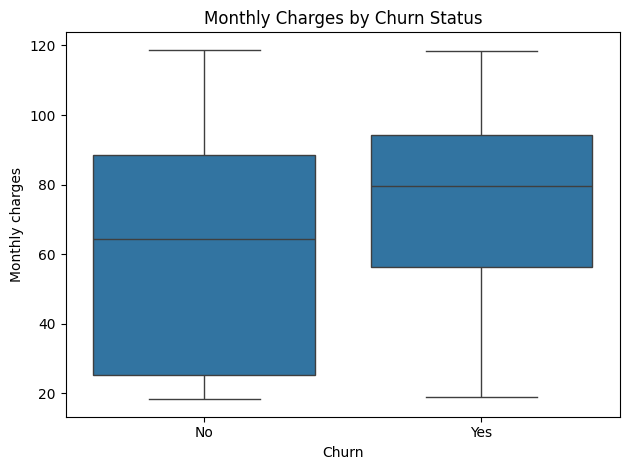

,count,mean,median
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


In [12]:
sns.boxplot(data=df_clean, x="Churn", y="MonthlyCharges", order=["No", "Yes"])
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly charges")
plt.tight_layout()
plt.show()

display(
    df_clean.groupby("Churn", observed=False)["MonthlyCharges"]
    .agg(["count", "mean", "median"])
    .round(2)
)

## 10. Churn by support and security services

,category,churn_rate_pct,feature
0,No,41.64,TechSupport
1,Yes,15.17,TechSupport
2,No internet service,7.40,TechSupport


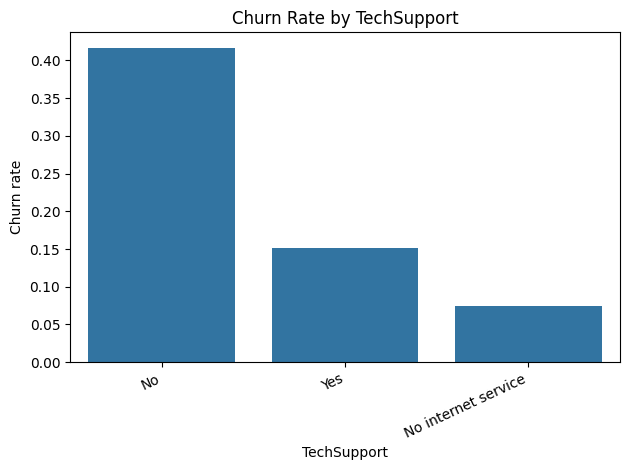

,category,churn_rate_pct,feature
0,No,41.77,OnlineSecurity
1,Yes,14.61,OnlineSecurity
2,No internet service,7.40,OnlineSecurity


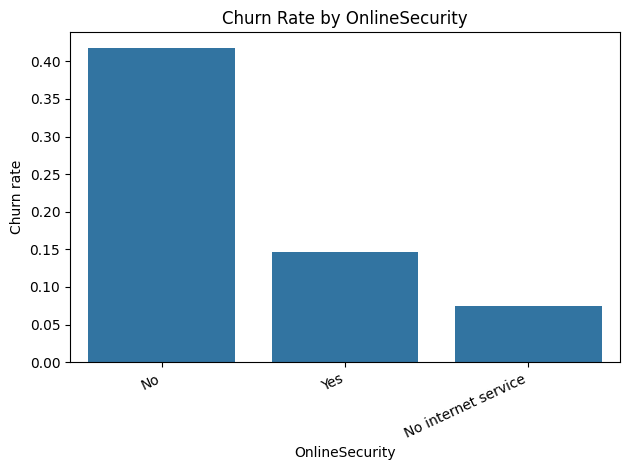

,category,churn_rate_pct,feature
0,Fiber optic,41.89,InternetService
1,DSL,18.96,InternetService
2,No,7.40,InternetService


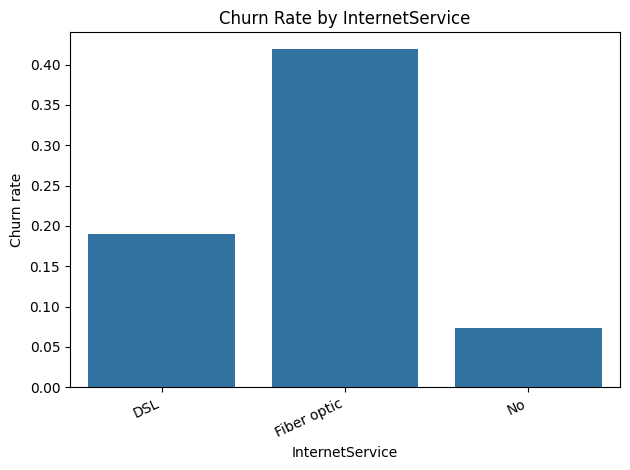

,category,churn_rate_pct,feature
0,Electronic check,45.29,PaymentMethod
1,Mailed check,19.11,PaymentMethod
2,Bank transfer (automatic),16.71,PaymentMethod
3,Credit card (automatic),15.24,PaymentMethod


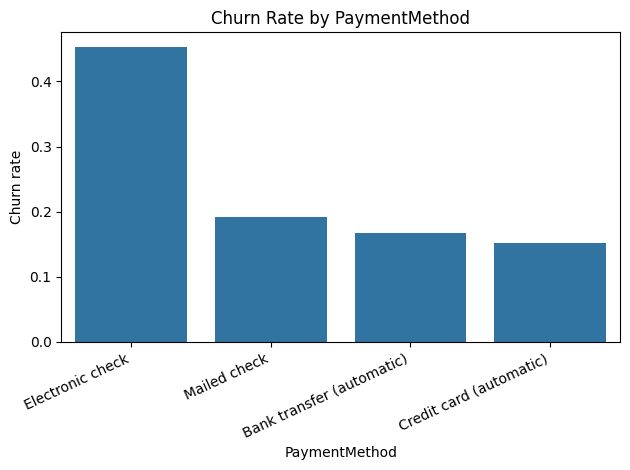

,category,churn_rate_pct,feature
0,Yes,33.57,PaperlessBilling
1,No,16.33,PaperlessBilling


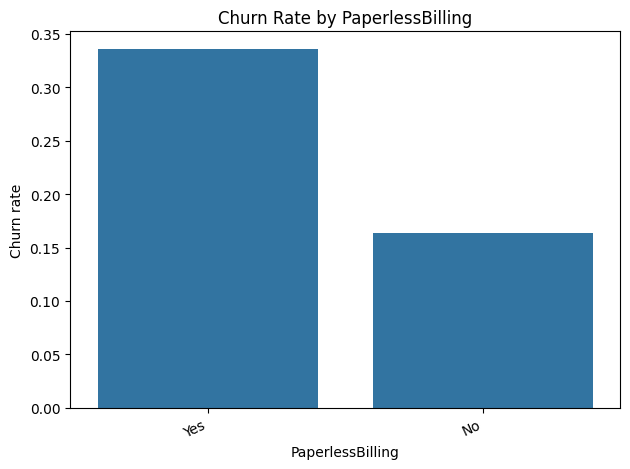

In [13]:
service_cols = ["TechSupport", "OnlineSecurity", "InternetService", "PaymentMethod", "PaperlessBilling"]
for col in service_cols:
    rates = df_clean.groupby(col, dropna=False)["ChurnFlag"].mean().sort_values(ascending=False)
    display((rates * 100).round(2).rename("churn_rate_pct").to_frame().assign(feature=col).reset_index().rename(columns={col: "category"}))

    plot_data = df_clean[[col, "ChurnFlag"]].copy()
    sns.barplot(data=plot_data, x=col, y="ChurnFlag", errorbar=None)
    plt.title(f"Churn Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Churn rate")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## 11. Save cleaned data for later steps

This writes a cleaned CSV that we can use for PostgreSQL, machine learning, and Power BI. Review the missing `TotalCharges` records first and decide whether to keep them, impute them, or exclude them from a specific analysis.

In [15]:
from pathlib import Path

# Save the cleaned dataset inside the InsightIQ project
OUTPUT_PATH = Path("data/telco_churn_cleaned.csv")

# Create the data folder if it doesn't exist
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

# Save the cleaned dataset
df_clean.to_csv(OUTPUT_PATH, index=False)

print(f"Saved successfully: {OUTPUT_PATH.resolve()}")
print(f"Cleaned dataset shape: {df_clean.shape}")

Saved successfully: C:\Users\91870\Desktop\InsightIQ\data\telco_churn_cleaned.csv
Cleaned dataset shape: (7043, 23)


In [17]:
# 1. Overall churn rate
print("1. OVERALL CHURN RATE")
print(f"{df_clean['ChurnFlag'].mean() * 100:.2f}%")

# 2. Contract type with the highest churn rate
print("\n2. CHURN BY CONTRACT TYPE")

contract_churn = (
    df_clean.groupby("Contract", observed=False)["ChurnFlag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(contract_churn.rename("Churn Rate (%)").round(2))

print("Highest churn:", contract_churn.idxmax())

# 3. Tenure group with the highest churn rate
print("\n3. CHURN BY TENURE GROUP")

tenure_churn = (
    df_clean.groupby("TenureGroup", observed=False)["ChurnFlag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(tenure_churn.rename("Churn Rate (%)").round(2))

print("Highest churn:", tenure_churn.idxmax())

# 4. Monthly charges by churn status
print("\n4. MONTHLY CHARGES BY CHURN STATUS")

charges = df_clean.groupby("Churn", observed=False)["MonthlyCharges"].agg(
    ["mean", "median", "count"]
)

display(charges.round(2))

# 5. Other patterns worth investigating
print("\n5. OTHER PATTERNS: CHURN BY PAYMENT METHOD")

payment_churn = (
    df_clean.groupby("PaymentMethod", observed=False)["ChurnFlag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(payment_churn.rename("Churn Rate (%)").round(2))

1. OVERALL CHURN RATE
26.54%

2. CHURN BY CONTRACT TYPE


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn Rate (%), dtype: float64

Highest churn: Month-to-month

3. CHURN BY TENURE GROUP


TenureGroup
0–6      52.94
7–12     35.89
13–24    28.71
25–48    20.39
49–60    14.42
61–72     6.61
Name: Churn Rate (%), dtype: float64

Highest churn: 0–6

4. MONTHLY CHARGES BY CHURN STATUS


,mean,median,count
Churn,,,
No,61.27,64.43,5174
Yes,74.44,79.65,1869



5. OTHER PATTERNS: CHURN BY PAYMENT METHOD


PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn Rate (%), dtype: float64